# Telco Customer Churn — Random Forest vs XGBoost

**Goal:** predict which telecom subscribers will churn, with a leakage-free ensemble-learning workflow, and clear the brief's bar of **ROC-AUC > 0.80**.

| # | Section | Key question |
|---|---|---|
| 1 | Load & audit | What is in the data, and what is broken? |
| 2 | Cleaning | How should the blank `TotalCharges` values be handled? |
| 3 | EDA | Who churns? |
| 4 | Split & pipelines | `OneHotEncoder`, stratified 80/20, leakage-safe pipelines |
| 5 | Imbalance strategies | None vs class weighting vs SMOTE, compared by cross-validation |
| 6 | Hyper-parameter tuning | `RandomizedSearchCV` for Random Forest and XGBoost (+ a logistic-regression yardstick) |
| 7 | Test-set evaluation | ROC-AUC with confidence intervals, ROC and PR curves, confusion matrices |
| 8 | Operating threshold & business view | Choosing a cut-off, gains / lift |
| 9 | Calibration | Can the scores be read as probabilities? |
| 10 | Feature importance | Top-10 drivers, four independent methods |
| 11 | Conclusions | |

**Conventions.** Every preprocessing step (encoding, SMOTE, weighting) lives inside a `Pipeline`, so it is re-fitted on training folds only. The test set is used for model *evaluation* only,
never for choosing a model, a strategy, a hyper-parameter or a threshold.

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint, uniform, loguniform

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, brier_score_loss,
                             log_loss, classification_report, confusion_matrix, f1_score, precision_score, recall_score,
                             accuracy_score, balanced_accuracy_score, matthews_corrcoef)
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate, cross_val_predict,
                                     RandomizedSearchCV, GridSearchCV)
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline            # imbalanced-learn pipeline: resamplers only act during fit()
import shap

RS = 42
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Load and audit the data

The IBM Telco sample: one row per subscriber, with demographics, subscribed services, account information and the label `Churn` (did the customer leave within the last month?).

In [2]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
try:
    raw = pd.read_csv(URL); source = "URL"
except Exception:
    raw = pd.read_csv("telco.csv"); source = "local file"
print(f"Loaded from {source}: shape = {raw.shape}")
raw.head()

Loaded from URL: shape = (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.65,Yes


In [3]:
audit = pd.DataFrame({"dtype": raw.dtypes.astype(str), "n_missing": raw.isna().sum(), "n_unique": raw.nunique()})
display(audit)
print("Duplicate customer IDs:", raw["customerID"].duplicated().sum(), "| fully duplicated rows:", raw.duplicated().sum())
print("\nChurn balance:"); display(raw["Churn"].value_counts().to_frame("rows").assign(share=lambda d: d.rows / d.rows.sum()))

,dtype,n_missing,n_unique
customerID,str,0,7043
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


Duplicate customer IDs: 0 | fully duplicated rows: 0

Churn balance:


,rows,share
Churn,,
No,5174,0.7346
Yes,1869,0.2654


**Audit findings**

- `TotalCharges` is stored as **text**, although it is a dollar amount. Something non-numeric is hiding in it; we look at that next.
- `isna()` reports zero nulls everywhere, so the "nulls" mentioned in the brief must be *blank strings*, which pandas does not count as missing.
- The target is **imbalanced** (≈ 73.5 % stay / 26.5 % churn), so plain accuracy would be misleading (a model that always says "stays" scores ≈ 73.5 %).
- No duplicate customers.

## 2. Cleaning: `TotalCharges`

Convert to numeric with `errors="coerce"` so that anything unparsable becomes `NaN`, then examine exactly which rows are affected *before* deciding how to fill them.

In [4]:
df = raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")

bad = df[df["TotalCharges"].isna()]
print(f"Rows with unparsable TotalCharges: {len(bad)}")
display(bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])
print("tenure values among these rows:", bad["tenure"].unique(), "| churn values:", bad["Churn"].unique())

Rows with unparsable TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.5500,NaN,No
753,3115-CZMZD,0,20.2500,NaN,No
936,5709-LVOEQ,0,80.8500,NaN,No
1082,4367-NUYAO,0,25.7500,NaN,No
1340,1371-DWPAZ,0,56.0500,NaN,No
3331,7644-OMVMY,0,19.8500,NaN,No
3826,3213-VVOLG,0,25.3500,NaN,No
4380,2520-SGTTA,0,20.0000,NaN,No
5218,2923-ARZLG,0,19.7000,NaN,No
6670,4075-WKNIU,0,73.3500,NaN,No


tenure values among these rows: [0] | churn values: <StringArray>
['No']
Length: 1, dtype: str


All 11 affected rows have **`tenure == 0`**: these are brand-new customers who have not yet been billed, so their cumulative charge is genuinely **\$0**, not an unknown value. (None of them churned either.)
Median imputation would invent roughly \$1,400 of billing history for customers with no history, so the correct fix is to fill with **0**. We assert the rule rather than assume it:

In [5]:
assert df.loc[df["TotalCharges"].isna(), "tenure"].eq(0).all(), "unexpected missing TotalCharges outside tenure==0"
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

# other tidy-ups
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})        # a binary flag: treat as categorical
df["Churn"] = (df["Churn"] == "Yes").astype(int)                          # target: 1 = churned
df = df.drop(columns="customerID")                                        # identifier, no predictive meaning

# sanity check: TotalCharges should be roughly tenure x MonthlyCharges
approx = df["tenure"] * df["MonthlyCharges"]
print("corr(TotalCharges, tenure x MonthlyCharges) =", round(np.corrcoef(df["TotalCharges"], approx)[0, 1], 4))
print("Remaining nulls:", int(df.isna().sum().sum()))

TARGET = "Churn"
X = df.drop(columns=TARGET); y = df[TARGET]
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print(f"\n{len(cat_cols)} categorical features, {len(num_cols)} numeric features: {num_cols}")

corr(TotalCharges, tenure x MonthlyCharges) = 0.9996
Remaining nulls: 0

16 categorical features, 3 numeric features: ['tenure', 'MonthlyCharges', 'TotalCharges']


Note that `TotalCharges` is almost a deterministic function of `tenure × MonthlyCharges` (correlation ≈ 0.999). Tree ensembles are insensitive to this redundancy, but it matters when *interpreting* importances
later (credit is split between correlated features).

## 3. Exploratory data analysis

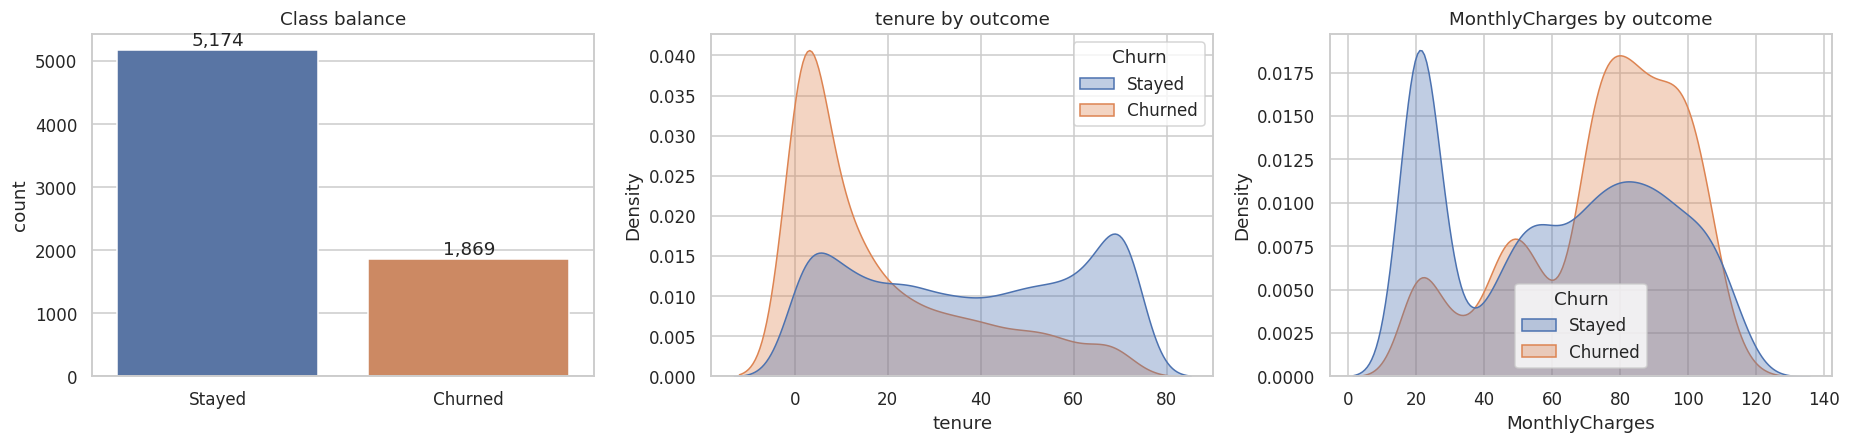

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.countplot(x=y.map({0: "Stayed", 1: "Churned"}), ax=axes[0], hue=y.map({0: "Stayed", 1: "Churned"}), legend=False)
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
axes[0].set_title("Class balance"); axes[0].set_xlabel("")

for ax, col in zip(axes[1:], ["tenure", "MonthlyCharges"]):
    sns.kdeplot(data=df, x=col, hue=df[TARGET].map({0: "Stayed", 1: "Churned"}), fill=True, common_norm=False, alpha=.35, ax=ax)
    ax.set_title(f"{col} by outcome")
plt.tight_layout(); plt.show()

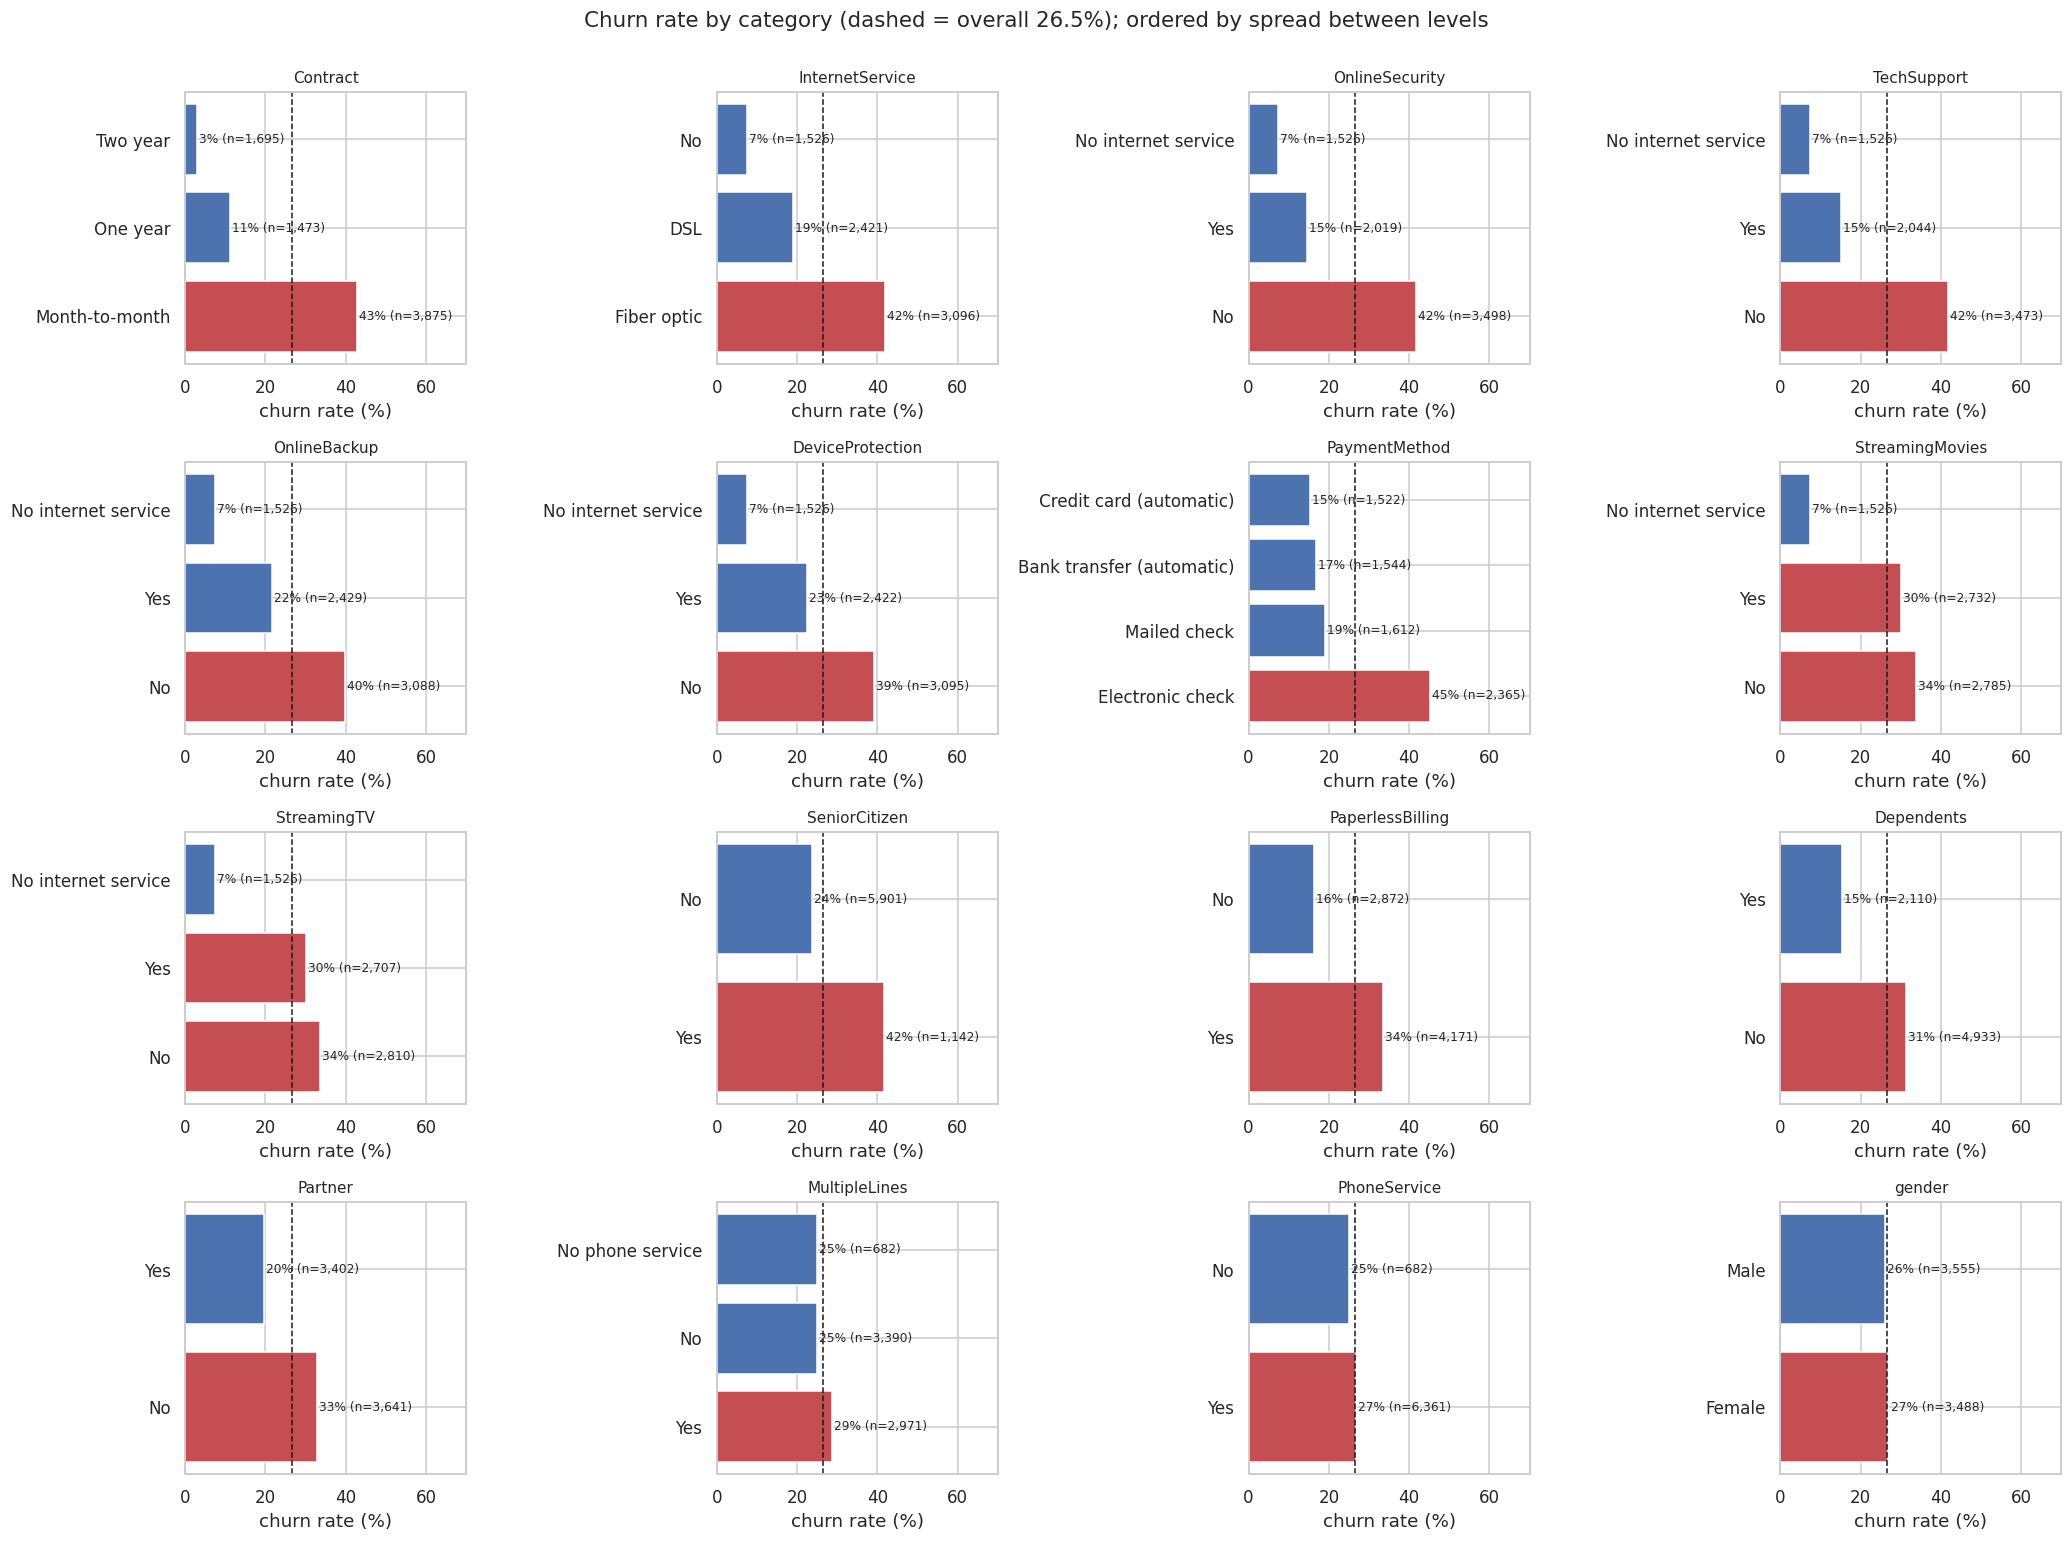

In [7]:
# churn rate within each level of every categorical feature
rows = []
for c in cat_cols:
    g = df.groupby(c)[TARGET].agg(["mean", "size"]).reset_index().rename(columns={c: "level"})
    g["feature"] = c; rows.append(g)
rates = pd.concat(rows)
overall = y.mean()

order = (rates.groupby("feature")["mean"].agg(lambda s: s.max() - s.min()).sort_values(ascending=False).index.tolist())
fig, axes = plt.subplots(4, 4, figsize=(19, 14)); axes = axes.ravel()
for ax, feat in zip(axes, order):
    g = rates[rates.feature == feat].sort_values("mean", ascending=False)
    ax.barh(g["level"], g["mean"] * 100, color=np.where(g["mean"] > overall, "C3", "C0"))
    ax.axvline(overall * 100, color="k", ls="--", lw=1)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m * 100 + .5, i, f"{m:.0%} (n={n:,})", va="center", fontsize=8)
    ax.set_title(feat, fontsize=10); ax.set_xlim(0, 70); ax.set_xlabel("churn rate (%)")
for ax in axes[len(order):]: ax.axis("off")
plt.suptitle(f"Churn rate by category (dashed = overall {overall:.1%}); ordered by spread between levels", y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

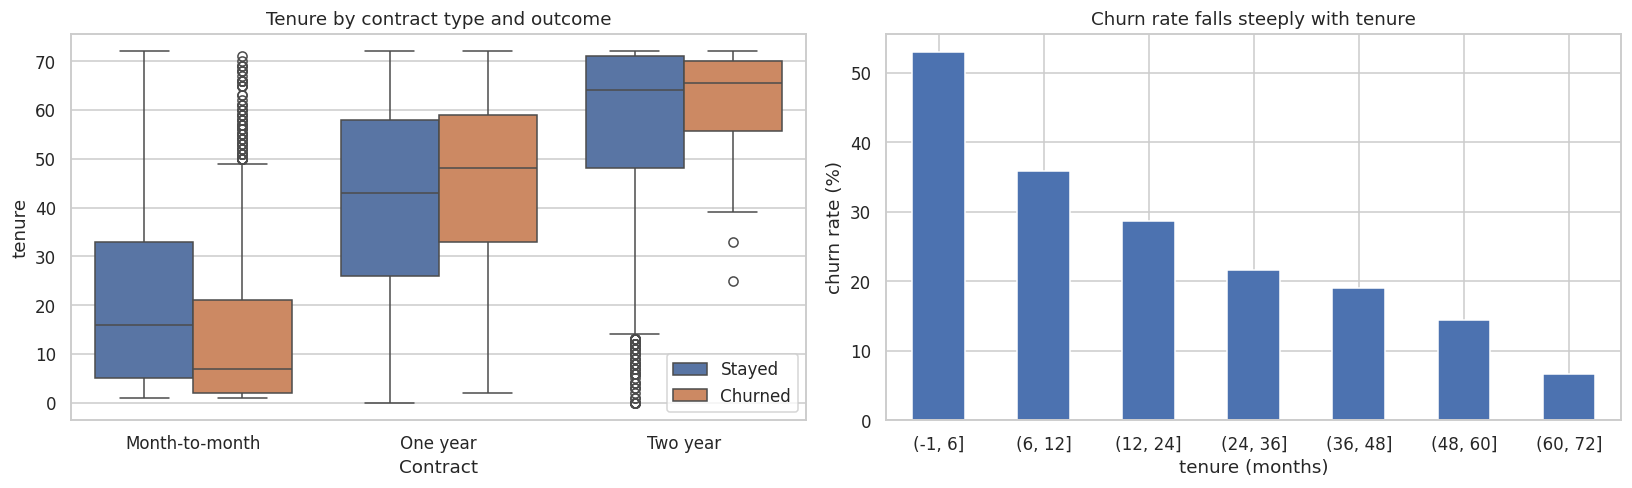

,tenure,MonthlyCharges,TotalCharges
corr with churn,-0.3522,0.1934,-0.1983


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
sns.boxplot(data=df, x="Contract", y="tenure", hue=df[TARGET].map({0: "Stayed", 1: "Churned"}), ax=axes[0])
axes[0].set_title("Tenure by contract type and outcome"); axes[0].legend(title="")

bins = pd.cut(df["tenure"], [-1, 6, 12, 24, 36, 48, 60, 72])
(df.groupby(bins, observed=True)[TARGET].mean() * 100).plot.bar(ax=axes[1], color="C0")
axes[1].set_ylabel("churn rate (%)"); axes[1].set_xlabel("tenure (months)"); axes[1].set_title("Churn rate falls steeply with tenure")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

num_corr = df[num_cols + [TARGET]].corr()
display(num_corr[TARGET].drop(TARGET).to_frame("corr with churn").T)

**What the EDA says**

- **Contract type is the dominant signal.** Month-to-month customers churn at ≈ 43 %, one-year at ≈ 11 % and two-year at only ≈ 3 %.
- **New customers leave; long-standing ones stay.** Tenure has the strongest numeric correlation with churn (r ≈ −0.35), and churn falls steeply as tenure grows.
- **Fibre-optic internet is a risk segment** (≈ 42 % churn, vs ≈ 19 % on DSL and ≈ 7 % with no internet), as are customers **without online security or tech support** (≈ 42 % each, vs ≈ 15 % with them) and those who **pay by electronic check** (≈ 45 %, vs 15–19 % for the other methods).
- **Demographics are weak:** gender (26 % vs 27 %) and phone service make almost no difference. Senior citizens churn more (42 % vs 24 %), but they are only 16 % of customers and are heavily concentrated in the risky segments (73 % have fibre-optic internet vs 38 % of non-seniors; 52 % pay by electronic check vs 30 %; 71 % are month-to-month vs 52 %), so much of that association is likely shared with other features.
- Higher monthly charges go with more churn (r ≈ +0.19). `TotalCharges` correlates *negatively* (r ≈ −0.20) only because it mostly measures tenure.

These are raw, one-variable associations. The models below will tell us which survive once the features are considered together.

## 4. Train / test split and pipeline design

**Split.** 80 / 20, stratified on `Churn` so both halves keep the 26.5 % churn rate. The 20 % test set is locked away until Section 7.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RS)
print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print(f"Churn rate  train = {y_train.mean():.3%} | test = {y_test.mean():.3%}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
SPW = (y_train == 0).sum() / (y_train == 1).sum()       # negatives / positives = XGBoost's scale_pos_weight
print(f"scale_pos_weight = {SPW:.3f}")

Train: (5634, 19)   Test: (1409, 19)
Churn rate  train = 26.535% | test = 26.544%
scale_pos_weight = 2.769


**Pipelines.** Three ways of handling the imbalance, each a complete pipeline:

| Strategy | What it does | Pipeline |
|---|---|---|
| `none` | nothing (reference) | OneHotEncoder → model |
| `weight` | penalise errors on churners more: `class_weight="balanced_subsample"` (RF) / `scale_pos_weight` (XGBoost) | OneHotEncoder → model |
| `smote` | synthesise new churner rows by interpolating between neighbours | OrdinalEncoder → **SMOTENC** → OneHotEncoder → model |

Why the odd order for SMOTE? Plain `SMOTE` interpolates numerically, so running it *after* one-hot encoding produces nonsense like "0.37 of a fibre-optic customer". `SMOTENC` ("nominal + continuous") is the variant built for mixed data:
it needs to know which columns are categorical, so it runs on ordinal codes first, and the one-hot encoding is done afterwards on clean, whole categories. Both resampling and weighting act **only while fitting**; validation folds and the test set are never resampled.

In [10]:
def make_pipe(model, strategy):
    n_cat = len(cat_cols)
    if strategy == "smote":
        ordinal = ColumnTransformer([("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols)],
                                    remainder="passthrough")          # -> categorical codes first, numeric after
        onehot = ColumnTransformer([("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(range(n_cat)))],
                                   remainder="passthrough")
        steps = [("ord", ordinal), ("smote", SMOTENC(categorical_features=list(range(n_cat)), random_state=RS)),
                 ("ohe", onehot), ("m", model)]
    else:
        pre = ColumnTransformer([("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)],
                                remainder="passthrough", verbose_feature_names_out=False)
        steps = [("pre", pre), ("m", model)]
    return Pipeline(steps)


def make_model(kind, strategy, **params):
    if kind == "rf":
        m = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=1, random_state=RS,
                                   class_weight="balanced_subsample" if strategy == "weight" else None)
    else:
        m = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, eval_metric="logloss", tree_method="hist",
                          n_jobs=1, random_state=RS, scale_pos_weight=SPW if strategy == "weight" else 1.0)
    m.set_params(**params)
    return make_pipe(m, strategy)


def make_lr(C=1.0):
    pre = ColumnTransformer([("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
                             ("num", StandardScaler(), num_cols)], verbose_feature_names_out=False)
    return Pipeline([("pre", pre), ("m", LogisticRegression(C=C, max_iter=3000, class_weight="balanced"))])


# --- helpers to get the encoded feature matrix / names out of either pipeline layout
def encoded_names(pipe):
    if "pre" in pipe.named_steps:
        return list(pipe.named_steps["pre"].get_feature_names_out())
    cats = pipe.named_steps["ord"].named_transformers_["ord"].categories_
    return [f"{c}_{v}" for c, cs in zip(cat_cols, cats) for v in cs] + num_cols

def encode(pipe, X_):
    Z = (pipe.named_steps["pre"].transform(X_) if "pre" in pipe.named_steps
         else pipe.named_steps["ohe"].transform(pipe.named_steps["ord"].transform(X_)))
    return pd.DataFrame(Z, columns=encoded_names(pipe), index=X_.index)

def to_feature(name):
    # map an encoded column such as 'Contract_Month-to-month' back to its source feature 'Contract'
    for c in cat_cols:
        if name.startswith(c + "_"): return c
    return name

# smoke test: both layouts produce the same set of columns, and SMOTENC output stays one-hot clean
p_w = make_model("rf", "weight").fit(X_train, y_train)
p_s = make_model("rf", "smote").fit(X_train, y_train)
print("encoded features (weight layout):", len(encoded_names(p_w)), "| (smote layout):", len(encoded_names(p_s)))
print("same columns:", sorted(encoded_names(p_w)) == sorted(encoded_names(p_s)))
print("train churn rate before SMOTE:", round(y_train.mean(), 3), "→ after SMOTENC: 0.500 (classes balanced 1:1 during fit)")
encode(p_w, X_train.head(3)).T.head(12)

encoded features (weight layout): 46 | (smote layout): 46
same columns: True
train churn rate before SMOTE: 0.265 → after SMOTENC: 0.500 (classes balanced 1:1 during fit)


,3738,3151,4860
gender_Female,0.0000,0.0000,0.0000
gender_Male,1.0000,1.0000,1.0000
SeniorCitizen_No,1.0000,1.0000,1.0000
SeniorCitizen_Yes,0.0000,0.0000,0.0000
Partner_No,1.0000,0.0000,0.0000
Partner_Yes,0.0000,1.0000,1.0000
Dependents_No,1.0000,0.0000,0.0000
Dependents_Yes,0.0000,1.0000,1.0000
PhoneService_No,1.0000,0.0000,1.0000
PhoneService_Yes,0.0000,1.0000,0.0000


## 5. Which imbalance strategy? (5-fold cross-validation on the training set)

Each of Random Forest and XGBoost is trained three ways with the *same* default hyper-parameters and the *same* folds, so differences come from the strategy alone. We report ROC-AUC (the target metric) but also PR-AUC,
precision, recall and F1 at the default 0.5 threshold, because that is where imbalance handling actually shows up. A regularised logistic regression is included as a simple yardstick.

In [11]:
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1", "recall": "recall", "precision": "precision"}
names = {"rf": "Random Forest", "xgb": "XGBoost"}
cv_store, rows = {}, []
for kind in ["rf", "xgb"]:
    for strat in ["none", "weight", "smote"]:
        r = cross_validate(make_model(kind, strat), X_train, y_train, cv=cv, scoring=scoring)
        cv_store[(kind, strat)] = r
        rows.append({"Model": names[kind], "Strategy": strat, **{m: r[f"test_{m}"].mean() for m in scoring},
                     "ROC-AUC sd": r["test_roc_auc"].std(ddof=1)})
r = cross_validate(make_lr(), X_train, y_train, cv=cv, scoring=scoring)
cv_store[("lr", "weight")] = r
rows.append({"Model": "Logistic Regression", "Strategy": "weight", **{m: r[f"test_{m}"].mean() for m in scoring}, "ROC-AUC sd": r["test_roc_auc"].std(ddof=1)})

strat_df = pd.DataFrame(rows).set_index(["Model", "Strategy"])
strat_df.columns = ["ROC-AUC", "PR-AUC", "F1", "Recall", "Precision", "ROC-AUC sd"]
display(strat_df.style.format("{:.4f}").background_gradient(cmap="Greens", subset=["ROC-AUC", "PR-AUC", "F1", "Recall"]))

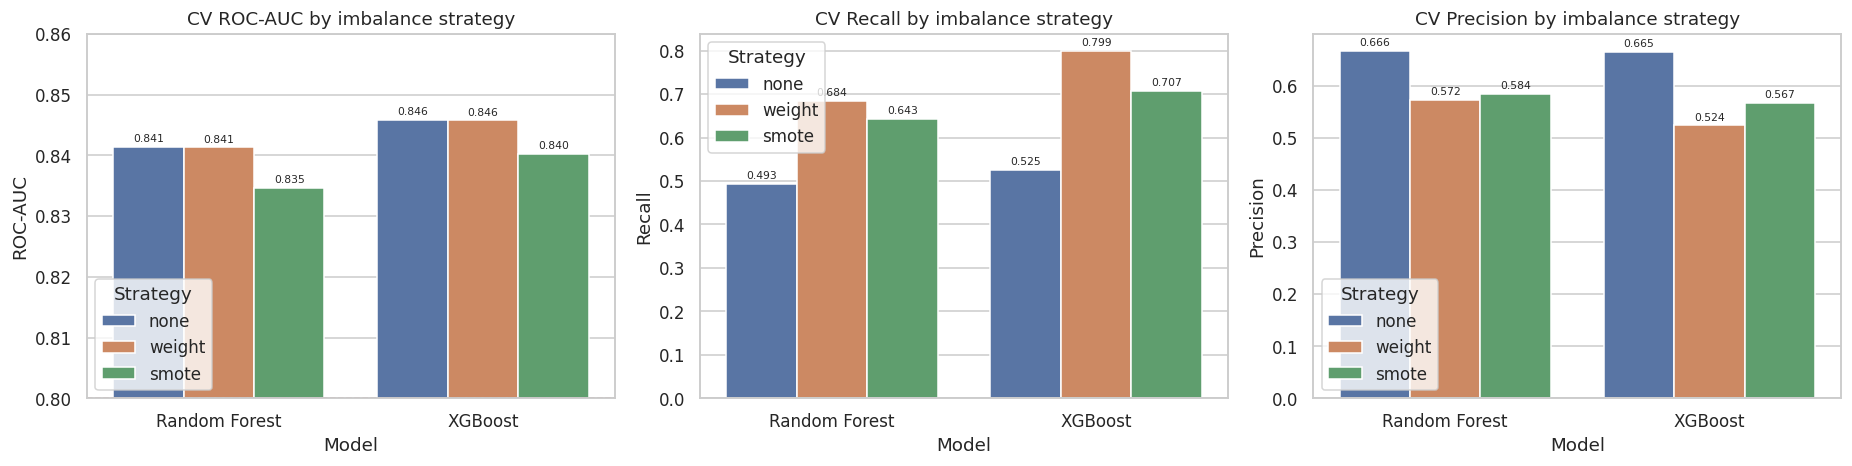

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
plot_df = strat_df.drop(index="Logistic Regression", level=0).reset_index()
for ax, metric in zip(axes, ["ROC-AUC", "Recall", "Precision"]):
    sns.barplot(data=plot_df, x="Model", y=metric, hue="Strategy", ax=ax)
    ax.set_title(f"CV {metric} by imbalance strategy")
    if metric == "ROC-AUC": ax.set_ylim(.80, .86); ax.axhline(.80, color="r", ls="--", lw=1)
    for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2)
plt.tight_layout(); plt.show()

# paired fold-level differences in AUC
pd_rows = []
for kind in ["rf", "xgb"]:
    a = cv_store[(kind, "none")]["test_roc_auc"]; w = cv_store[(kind, "weight")]["test_roc_auc"]; s = cv_store[(kind, "smote")]["test_roc_auc"]
    for lab, d in [("weight − none", w - a), ("smote − weight", s - w)]:
        pd_rows.append({"Model": names[kind], "AUC difference": lab, "mean Δ": d.mean(), "SE": d.std(ddof=1) / np.sqrt(len(d)), "folds A better": int((d > 0).sum())})
display(pd.DataFrame(pd_rows).set_index(["Model", "AUC difference"]).style.format({"mean Δ": "{:+.4f}", "SE": "{:.4f}", "folds A better": "{:.0f}/5"}))

In [13]:
# decision rule (fixed in advance): choose SMOTE only if it beats class weighting on CV ROC-AUC by more than 0.002; otherwise prefer the simpler weighting
chosen = {}
for kind in ["rf", "xgb"]:
    auc_w = cv_store[(kind, "weight")]["test_roc_auc"].mean(); auc_s = cv_store[(kind, "smote")]["test_roc_auc"].mean()
    chosen[kind] = "smote" if auc_s > auc_w + 0.002 else "weight"
    print(f"{names[kind]:14s} weight AUC = {auc_w:.4f} | SMOTE AUC = {auc_s:.4f}  →  chosen strategy: {chosen[kind]}")

Random Forest  weight AUC = 0.8413 | SMOTE AUC = 0.8347  →  chosen strategy: weight
XGBoost        weight AUC = 0.8457 | SMOTE AUC = 0.8402  →  chosen strategy: weight


**Reading the strategy comparison**

- **Class weighting leaves ROC-AUC untouched, but changes what the model does at a 0.5 cut-off.** The AUC difference vs no balancing is −0.0001 (SE 0.0005) for both models, which makes sense: re-weighting changes the *scale* of the scores far more than their *ranking*.
  What moves is recall: Random Forest 0.49 → 0.68 and XGBoost 0.53 → 0.80, at the price of precision (0.67 → 0.57 and 0.66 → 0.52). F1 for the churn class improves for both (0.566 → 0.623 and 0.587 → 0.633).
- **SMOTENC is consistently slightly worse.** It lowers CV ROC-AUC by about 0.006 (Random Forest: worse in 5 of 5 folds; XGBoost: worse in 4 of 5), and gives less recall than weighting at the 0.5 cut-off (0.64 and 0.71 vs 0.68 and 0.80). With ~5,600 rows and a 1:2.8 imbalance, synthetic neighbours add little new information and blur the class boundary.
- **A plain logistic regression is a strong yardstick:** CV AUC 0.846, the same as default XGBoost (0.8457) and better than default Random Forest (0.841). Keep that in mind in the next sections.

By the pre-declared rule, **both ensembles use class weighting** (`class_weight="balanced_subsample"` and `scale_pos_weight ≈ 2.77`). Every configuration already clears the 0.80 target in cross-validation.

## 6. Hyper-parameter tuning (`RandomizedSearchCV`, 5-fold, scoring = ROC-AUC)

Random search over wide distributions is usually as good as a grid with a fraction of the cost. The search runs on the **training set only**; its best CV score is slightly optimistic (the winner was picked from many candidates),
which is exactly why the untouched test set is reserved for Section 7.

In [14]:
rf_space = {"m__n_estimators": randint(150, 401), "m__max_depth": [None, 6, 8, 10, 14],
            "m__min_samples_leaf": randint(1, 16), "m__min_samples_split": randint(2, 21),
            "m__max_features": ["sqrt", "log2", 0.3, 0.5]}
xgb_space = {"m__n_estimators": randint(100, 501), "m__learning_rate": loguniform(0.01, 0.2), "m__max_depth": randint(2, 7),
             "m__min_child_weight": randint(1, 11), "m__subsample": uniform(0.6, 0.4), "m__colsample_bytree": uniform(0.5, 0.5),
             "m__gamma": uniform(0, 2), "m__reg_lambda": loguniform(0.1, 10)}

rs_rf = RandomizedSearchCV(make_model("rf", chosen["rf"]), rf_space, n_iter=20, cv=cv, scoring="roc_auc", random_state=RS, n_jobs=1).fit(X_train, y_train)
rs_xgb = RandomizedSearchCV(make_model("xgb", chosen["xgb"]), xgb_space, n_iter=30, cv=cv, scoring="roc_auc", random_state=RS, n_jobs=1).fit(X_train, y_train)
gs_lr = GridSearchCV(make_lr(), {"m__C": np.logspace(-3, 2, 11)}, cv=cv, scoring="roc_auc").fit(X_train, y_train)

for nm, s, base in [("Random Forest", rs_rf, cv_store[("rf", chosen["rf"])]["test_roc_auc"].mean()),
                    ("XGBoost", rs_xgb, cv_store[("xgb", chosen["xgb"])]["test_roc_auc"].mean()),
                    ("Logistic Regression", gs_lr, cv_store[("lr", "weight")]["test_roc_auc"].mean())]:
    print(f"{nm:20s} default CV AUC = {base:.4f}  →  tuned CV AUC = {s.best_score_:.4f}")
    print("   best params:", {k.replace("m__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in s.best_params_.items()})

Random Forest        default CV AUC = 0.8413  →  tuned CV AUC = 0.8481
   best params: {'max_depth': 8, 'max_features': 0.3, 'min_samples_leaf': 10, 'min_samples_split': 17, 'n_estimators': 164}
XGBoost              default CV AUC = 0.8457  →  tuned CV AUC = 0.8495
   best params: {'colsample_bytree': np.float64(0.9703), 'gamma': np.float64(0.7951), 'learning_rate': np.float64(0.0472), 'max_depth': 2, 'min_child_weight': 9, 'n_estimators': 250, 'reg_lambda': np.float64(1.2103), 'subsample': np.float64(0.8783)}
Logistic Regression  default CV AUC = 0.8460  →  tuned CV AUC = 0.8462
   best params: {'C': np.float64(10.0)}


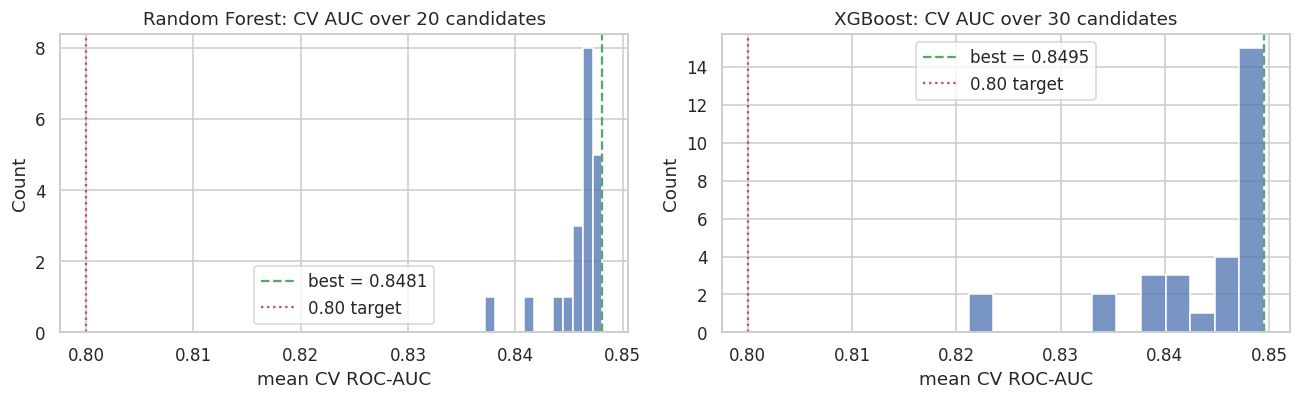

In [15]:
# how sensitive is performance to the search? distribution of CV AUC across all candidates
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, s, nm in [(axes[0], rs_rf, "Random Forest"), (axes[1], rs_xgb, "XGBoost")]:
    sc = s.cv_results_["mean_test_score"]
    sns.histplot(sc, bins=12, ax=ax, color="C0"); ax.axvline(s.best_score_, color="g", ls="--", label=f"best = {s.best_score_:.4f}")
    ax.axvline(.80, color="r", ls=":", label="0.80 target"); ax.set_title(f"{nm}: CV AUC over {len(sc)} candidates"); ax.set_xlabel("mean CV ROC-AUC"); ax.legend()
plt.tight_layout(); plt.show()

**What tuning bought us**

| Model | Default CV AUC | Tuned CV AUC |
|---|---|---|
| Random Forest | 0.8413 | **0.8481** |
| XGBoost | 0.8457 | **0.8495** |
| Logistic Regression | 0.8460 | 0.8462 |

The search found gains of about +0.004–0.007 AUC for the ensembles, and essentially none for logistic regression. The winning settings are telling: the best Random Forest is **shallow and heavily regularised** (depth 8, ≥ 10 samples per leaf) and the best XGBoost is a **depth-2 model** (learning rate ≈ 0.05, 250 trees).
Trees that shallow mean the signal here is largely additive with only low-order interactions, which is precisely the kind of structure a logistic regression can also capture, and explains why the three models finish so close together. Remember that these tuned CV scores are mildly optimistic (best of many candidates); the unbiased check is the test set.

## 7. Test-set evaluation

Models are now scored **once** on the 1,409 held-out customers. The headline metric is **ROC-AUC**, with a 95 % bootstrap confidence interval (2,000 resamples of the test set) so we can state whether the ">0.80" target is met with margin, not just on a point estimate.

In [16]:
final = {"Logistic Regression": gs_lr.best_estimator_, "Random Forest": rs_rf.best_estimator_, "XGBoost": rs_xgb.best_estimator_}
proba = {k: m.predict_proba(X_test)[:, 1] for k, m in final.items()}
y_t = y_test.values

# bootstrap
rng = np.random.default_rng(RS)
B = 2000
idx = rng.integers(0, len(y_t), size=(B, len(y_t)))
boot = {k: np.array([roc_auc_score(y_t[i], p[i]) for i in idx]) for k, p in proba.items()}

def best_fold_scores(s):
    i = s.best_index_
    return np.array([s.cv_results_[f"split{j}_test_score"][i] for j in range(5)])
cv_folds = {"Logistic Regression": best_fold_scores(gs_lr), "Random Forest": best_fold_scores(rs_rf), "XGBoost": best_fold_scores(rs_xgb)}

rows = []
for k, p in proba.items():
    yhat = (p >= 0.5).astype(int)
    rows.append({"Model": k,
                 "CV AUC (mean)": cv_folds[k].mean(), "CV AUC (worst fold)": cv_folds[k].min(),
                 "Test ROC-AUC": roc_auc_score(y_t, p), "95% CI low": np.percentile(boot[k], 2.5), "95% CI high": np.percentile(boot[k], 97.5),
                 "> 0.80 ?": "YES" if np.percentile(boot[k], 2.5) > 0.80 else "no",
                 "PR-AUC": average_precision_score(y_t, p), "Brier": brier_score_loss(y_t, p)})
res = pd.DataFrame(rows).set_index("Model")
display(res.style.format({c: "{:.4f}" for c in res.columns if c != "> 0.80 ?"}).background_gradient(subset=["Test ROC-AUC"], cmap="Greens"))

,CV AUC (mean),CV AUC (worst fold),Test ROC-AUC,95% CI low,95% CI high,> 0.80 ?,PR-AUC,Brier
Model,,,,,,,,
Logistic Regression,0.8462,0.8255,0.8408,0.8171,0.8622,YES,0.6271,0.1692
Random Forest,0.8481,0.8334,0.8438,0.8209,0.8645,YES,0.6561,0.1575
XGBoost,0.8495,0.8304,0.8460,0.8231,0.8667,YES,0.6644,0.1643


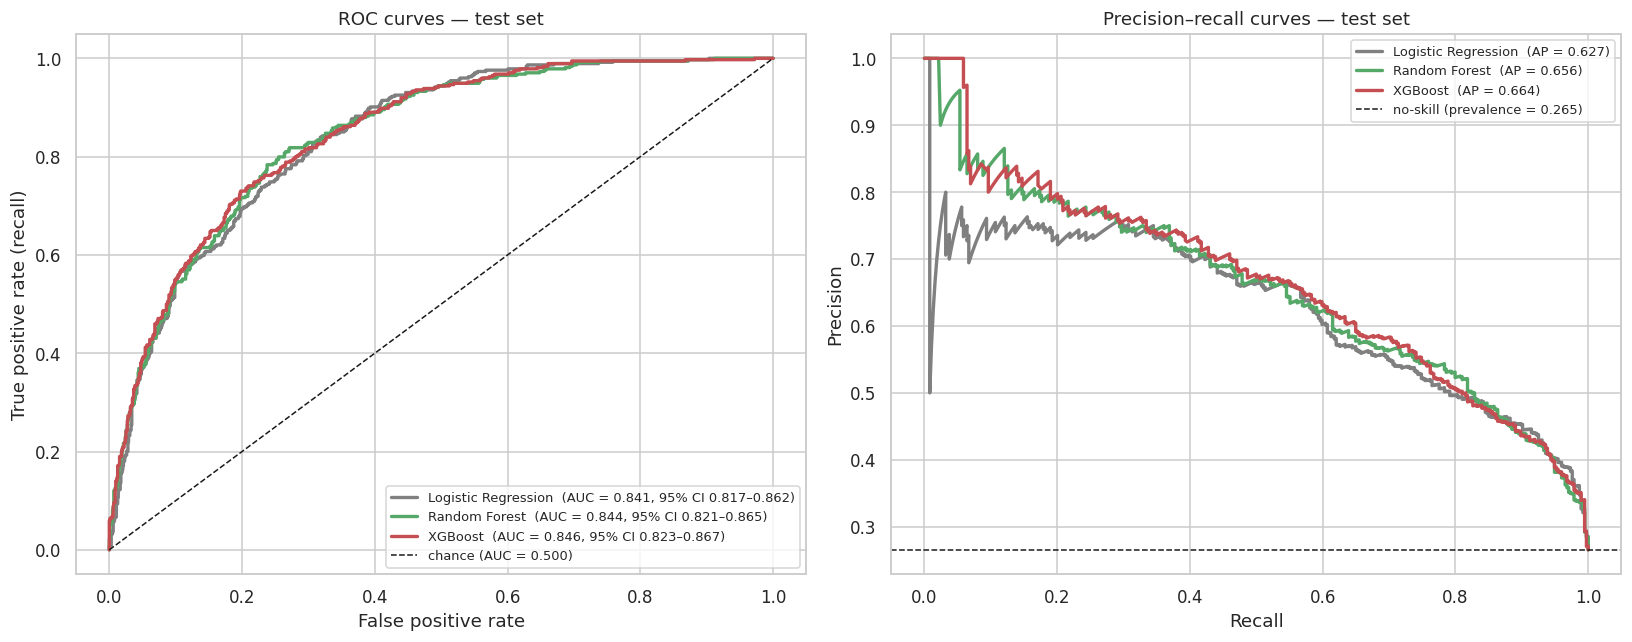

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
colors = {"Logistic Regression": "gray", "Random Forest": "C2", "XGBoost": "C3"}

ax = axes[0]
for k, p in proba.items():
    fpr, tpr, _ = roc_curve(y_t, p)
    ax.plot(fpr, tpr, lw=2.2, color=colors[k], label=f"{k}  (AUC = {roc_auc_score(y_t, p):.3f}, 95% CI {np.percentile(boot[k], 2.5):.3f}–{np.percentile(boot[k], 97.5):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="chance (AUC = 0.500)")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)"); ax.set_title("ROC curves — test set")
ax.legend(loc="lower right", fontsize=8.5)

ax = axes[1]
for k, p in proba.items():
    pr, rc, _ = precision_recall_curve(y_t, p)
    ax.plot(rc, pr, lw=2.2, color=colors[k], label=f"{k}  (AP = {average_precision_score(y_t, p):.3f})")
ax.axhline(y_t.mean(), color="k", ls="--", lw=1, label=f"no-skill (prevalence = {y_t.mean():.3f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision–recall curves — test set"); ax.legend(loc="upper right", fontsize=8.5)
plt.tight_layout(); plt.show()

In [18]:
# is the ordering of models real? paired bootstrap on the same resamples
rows = []
for a, b in [("XGBoost", "Random Forest"), ("XGBoost", "Logistic Regression"), ("Random Forest", "Logistic Regression")]:
    d = boot[a] - boot[b]
    rows.append({"Comparison (A − B)": f"{a} − {b}", "mean Δ AUC": d.mean(), "95% CI low": np.percentile(d, 2.5), "95% CI high": np.percentile(d, 97.5),
                 "A better in % of resamples": 100 * (d > 0).mean()})
display(pd.DataFrame(rows).set_index("Comparison (A − B)").style.format({"mean Δ AUC": "{:+.4f}", "95% CI low": "{:+.4f}", "95% CI high": "{:+.4f}", "A better in % of resamples": "{:.1f}%"}))

# where on the ROC curve do we operate? recall achievable at fixed false-alarm rates
rows = []
for k, p in proba.items():
    fpr, tpr, _ = roc_curve(y_t, p)
    rows.append({"Model": k, **{f"TPR @ FPR={f:.0%}": float(np.interp(f, fpr, tpr)) for f in [0.05, 0.10, 0.20, 0.30]}})
display(pd.DataFrame(rows).set_index("Model").style.format("{:.3f}"))

,mean Δ AUC,95% CI low,95% CI high,A better in % of resamples
Comparison (A − B),,,,
XGBoost − Random Forest,+0.0022,-0.0032,+0.0076,79.1%
XGBoost − Logistic Regression,+0.0053,-0.0012,+0.0118,94.2%
Random Forest − Logistic Regression,+0.0031,-0.0050,+0.0110,77.2%


,TPR @ FPR=5%,TPR @ FPR=10%,TPR @ FPR=20%,TPR @ FPR=30%
Model,,,,
Logistic Regression,0.369,0.548,0.695,0.810
Random Forest,0.372,0.543,0.717,0.829
XGBoost,0.388,0.551,0.730,0.816


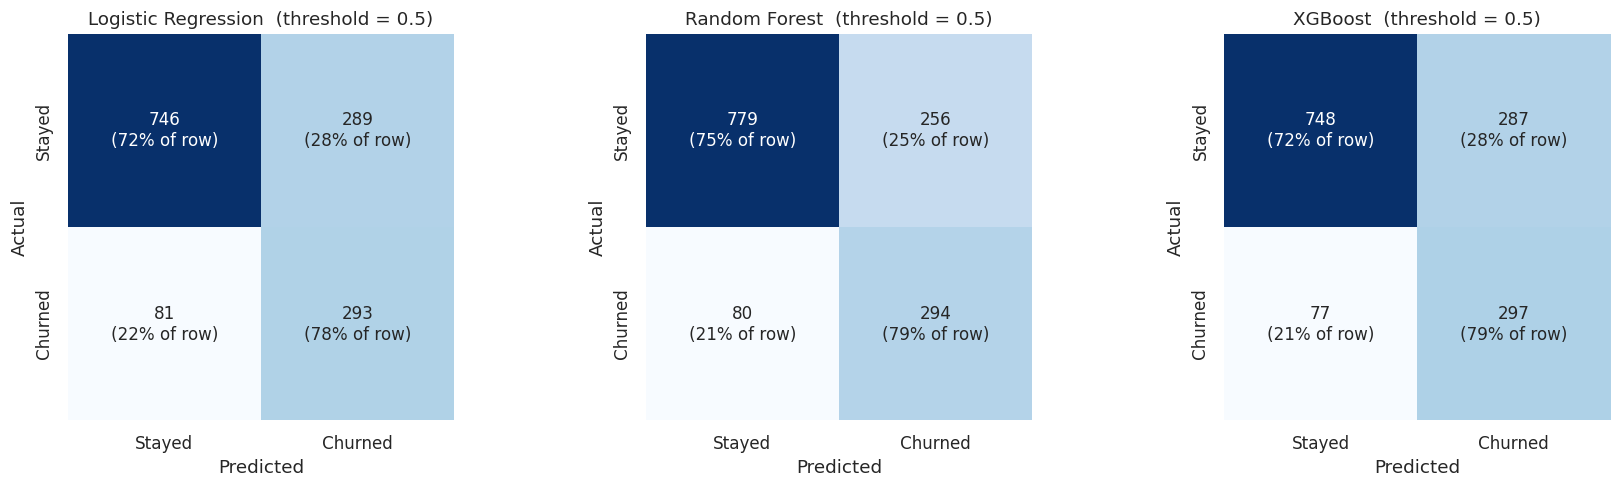

,Accuracy,Balanced acc.,Precision (churn),Recall (churn),F1 (churn),MCC
Model,,,,,,
Logistic Regression,0.7374,0.7521,0.5034,0.7834,0.6130,0.4522
Random Forest,0.7615,0.7694,0.5345,0.7861,0.6364,0.4877
XGBoost,0.7417,0.7584,0.5086,0.7941,0.6200,0.4632


In [19]:
# default 0.5 threshold: classification metrics + confusion matrices
rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (k, p) in zip(axes, proba.items()):
    yhat = (p >= 0.5).astype(int)
    rows.append({"Model": k, "Accuracy": accuracy_score(y_t, yhat), "Balanced acc.": balanced_accuracy_score(y_t, yhat),
                 "Precision (churn)": precision_score(y_t, yhat), "Recall (churn)": recall_score(y_t, yhat),
                 "F1 (churn)": f1_score(y_t, yhat), "MCC": matthews_corrcoef(y_t, yhat)})
    cm = confusion_matrix(y_t, yhat)
    sns.heatmap(cm, annot=np.array([[f"{v}\n({v/cm.sum(1)[i]:.0%} of row)" for v in row] for i, row in enumerate(cm)]), fmt="", cmap="Blues",
                cbar=False, square=True, xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"], ax=ax, annot_kws={"size": 11})
    ax.set_title(f"{k}  (threshold = 0.5)"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("Model").style.format("{:.4f}"))

**Does the model clear the ROC-AUC > 0.80 target?  Yes, comfortably.**

| Model | Test ROC-AUC | 95 % CI | Worst CV fold |
|---|---|---|---|
| XGBoost | **0.846** | 0.823 – 0.867 | 0.830 |
| Random Forest | 0.844 | 0.821 – 0.865 | 0.833 |
| Logistic Regression | 0.841 | 0.817 – 0.862 | 0.826 |

The **lower end of every confidence interval is above 0.80** (≈ 0.82), and every individual cross-validation fold also scored above 0.82, so the target is met with margin, not by luck of one split. Test AUC (0.846) is in line with CV AUC (0.850), so there is no sign of over-fitting to the tuning process.

**But the three models are statistically tied.** The paired bootstrap puts XGBoost ahead of Random Forest by +0.002 AUC (CI −0.003 to +0.008) and ahead of logistic regression by +0.005 (CI −0.001 to +0.012); both intervals include zero. XGBoost has a small edge on PR-AUC (0.664 vs 0.656 for RF and 0.627 for LR) and at low false-alarm rates (TPR at 20 % FPR: 0.73 vs 0.72 and 0.70), so it is the sensible primary model and was chosen on CV AUC, not on the test set. But the honest summary is that **the ensembles beat a well-tuned linear baseline by a hair, not by a margin**. On a dataset this size (~7k rows, ~19 raw features, mostly categorical and largely additive) that is a common finding.

**Why accuracy is not reported as the headline.** At the default 0.5 cut-off the models reach only 74–76 % accuracy, barely above the 73.5 % you get by predicting "stays" for everyone. They are doing something more useful than that: they catch ≈ 78–79 % of churners (recall) at the cost of precision ≈ 0.50–0.53, i.e. about one flagged customer in two is a real churner against a base rate of one in four. Section 8 shows how to tune that trade-off.

## 8. Operating threshold and the business view

ROC-AUC measures *ranking* quality and is threshold-free. To act on the model we must still choose a cut-off. The default 0.5 is arbitrary, and class weighting shifts the score scale, so we choose the threshold properly: on **out-of-fold
predictions from the training set** (never the test set), maximising F1 for the churn class. Then we check it on the test set. We do this for the model with the best CV AUC.

Model selected by CV ROC-AUC: XGBoost


F1-optimal threshold on out-of-fold training predictions: 0.58  (OOF F1 = 0.642, OOF ROC-AUC = 0.8488)


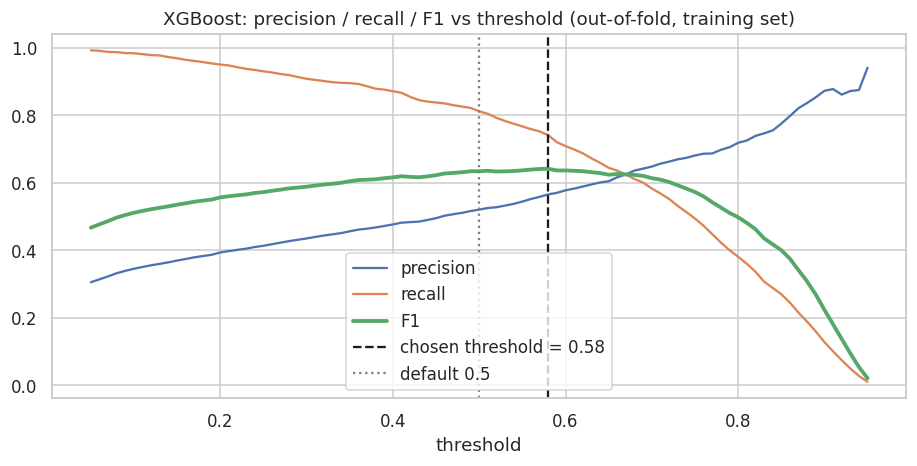

In [20]:
best_name = max(["Random Forest", "XGBoost"], key=lambda k: cv_folds[k].mean())
best_est = final[best_name]
print("Model selected by CV ROC-AUC:", best_name)

oof = cross_val_predict(clone(best_est), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
ths = np.linspace(0.05, 0.95, 91)
f1s = np.array([f1_score(y_train, oof >= t) for t in ths]); prs = np.array([precision_score(y_train, oof >= t, zero_division=0) for t in ths]); rcs = np.array([recall_score(y_train, oof >= t) for t in ths])
t_star = ths[f1s.argmax()]
print(f"F1-optimal threshold on out-of-fold training predictions: {t_star:.2f}  (OOF F1 = {f1s.max():.3f}, OOF ROC-AUC = {roc_auc_score(y_train, oof):.4f})")

fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.plot(ths, prs, label="precision", color="C0"); ax.plot(ths, rcs, label="recall", color="C1"); ax.plot(ths, f1s, label="F1", color="C2", lw=2.5)
ax.axvline(t_star, color="k", ls="--", label=f"chosen threshold = {t_star:.2f}"); ax.axvline(0.5, color="gray", ls=":", label="default 0.5")
ax.set_xlabel("threshold"); ax.set_title(f"{best_name}: precision / recall / F1 vs threshold (out-of-fold, training set)"); ax.legend(); plt.tight_layout(); plt.show()

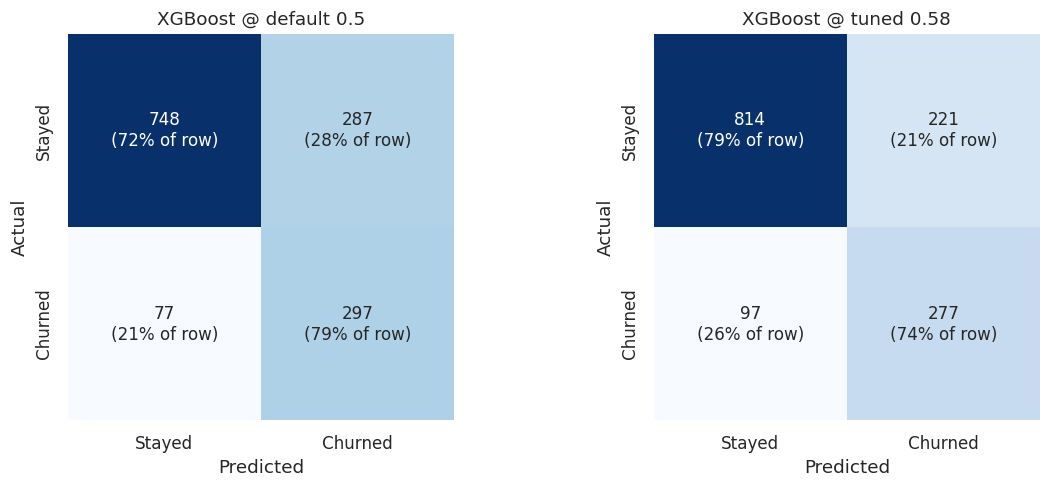

,Precision,Recall,F1,Accuracy,Customers flagged
Threshold,,,,,
default 0.5,0.509,0.794,0.620,0.742,584
tuned 0.58,0.556,0.741,0.635,0.774,498


Classification report at the tuned threshold (0.58):
              precision    recall  f1-score   support

      Stayed      0.894     0.786     0.837      1035
     Churned      0.556     0.741     0.635       374

    accuracy                          0.774      1409
   macro avg      0.725     0.764     0.736      1409
weighted avg      0.804     0.774     0.783      1409



In [21]:
p_best = proba[best_name]
rows, fig_axes = [], plt.subplots(1, 2, figsize=(11, 4.6))
fig, axes = fig_axes
for ax, (lab, t) in zip(axes, [("default 0.5", 0.5), (f"tuned {t_star:.2f}", t_star)]):
    yhat = (p_best >= t).astype(int)
    rows.append({"Threshold": lab, "Precision": precision_score(y_t, yhat), "Recall": recall_score(y_t, yhat), "F1": f1_score(y_t, yhat),
                 "Accuracy": accuracy_score(y_t, yhat), "Customers flagged": int(yhat.sum())})
    cm = confusion_matrix(y_t, yhat)
    sns.heatmap(cm, annot=np.array([[f"{v}\n({v/cm.sum(1)[i]:.0%} of row)" for v in row] for i, row in enumerate(cm)]), fmt="", cmap="Blues", cbar=False, square=True,
                xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"], ax=ax, annot_kws={"size": 11})
    ax.set_title(f"{best_name} @ {lab}"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("Threshold").style.format({"Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}", "Accuracy": "{:.3f}", "Customers flagged": "{:.0f}"}))
print(f"Classification report at the tuned threshold ({t_star:.2f}):")
print(classification_report(y_t, (p_best >= t_star).astype(int), target_names=["Stayed", "Churned"], digits=3))

### 8.1 Cumulative gains and lift: how well does the ranking focus a retention campaign?

If the retention team can only contact a fraction of the customer base, we want the churners concentrated at the top of the ranked list.

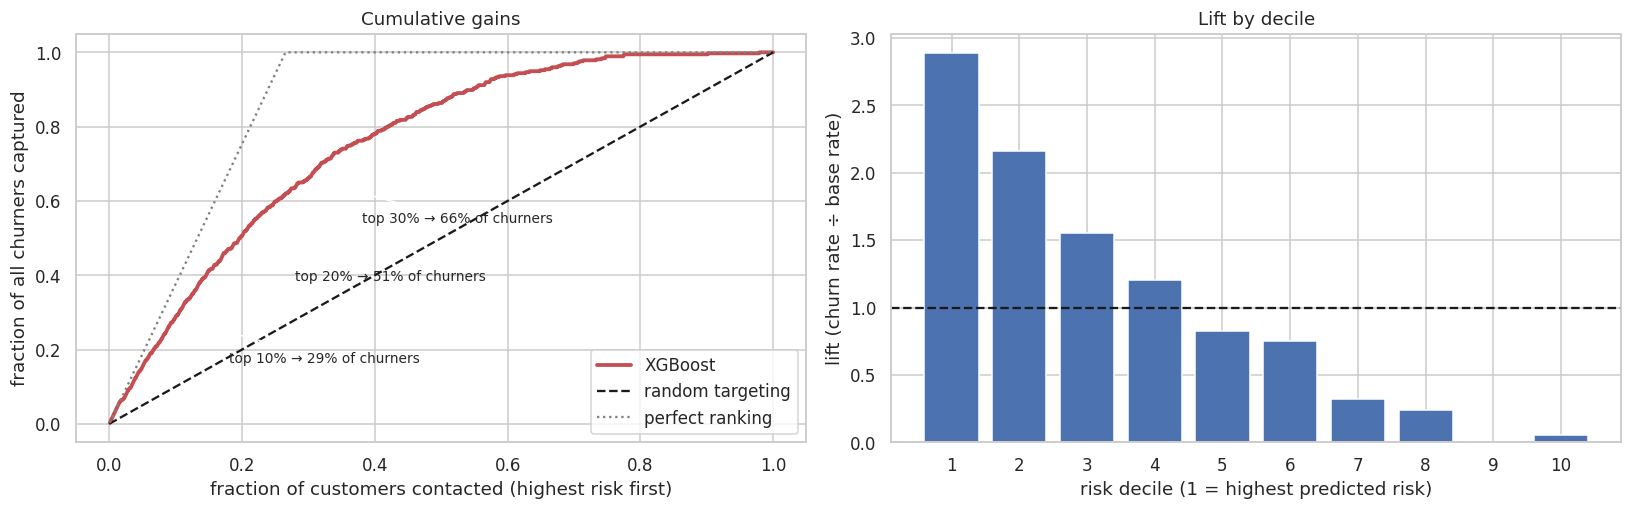

,customers,churners,churn rate,lift,cum. % of churners captured
decile,,,,,
1,141,108,76.6%,2.89,28.9%
2,141,81,57.4%,2.16,50.5%
3,141,58,41.1%,1.55,66.0%
4,141,45,31.9%,1.20,78.1%
5,141,31,22.0%,0.83,86.4%
6,141,28,19.9%,0.75,93.9%
7,141,12,8.5%,0.32,97.1%
8,141,9,6.4%,0.24,99.5%
9,141,0,0.0%,0.00,99.5%


In [22]:
order = np.argsort(-p_best)
y_sorted = y_t[order]
n = len(y_sorted); cum_tp = np.cumsum(y_sorted); frac = np.arange(1, n + 1) / n
gain = cum_tp / y_sorted.sum()

dec = pd.DataFrame({"decile": np.repeat(np.arange(1, 11), int(np.ceil(n / 10)))[:n], "y": y_sorted})
dtab = dec.groupby("decile")["y"].agg(customers="size", churners="sum")
dtab["churn rate"] = dtab.churners / dtab.customers
dtab["lift"] = dtab["churn rate"] / y_t.mean()
dtab["cum. % of churners captured"] = dtab.churners.cumsum() / dtab.churners.sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].plot(frac, gain, lw=2.5, color="C3", label=best_name)
axes[0].plot([0, 1], [0, 1], "k--", label="random targeting")
perfect = np.minimum(frac / y_sorted.mean(), 1); axes[0].plot(frac, perfect, color="gray", ls=":", label="perfect ranking")
for q in [0.1, 0.2, 0.3]:
    g = gain[int(q * n) - 1]; axes[0].annotate(f"top {q:.0%} → {g:.0%} of churners", (q, g), xytext=(q + .08, g - .12), arrowprops=dict(arrowstyle="->"), fontsize=9)
axes[0].set_xlabel("fraction of customers contacted (highest risk first)"); axes[0].set_ylabel("fraction of all churners captured"); axes[0].set_title("Cumulative gains"); axes[0].legend(loc="lower right")
axes[1].bar(dtab.index, dtab["lift"], color="C0"); axes[1].axhline(1, color="k", ls="--"); axes[1].set_xlabel("risk decile (1 = highest predicted risk)"); axes[1].set_ylabel("lift (churn rate ÷ base rate)")
axes[1].set_title("Lift by decile"); axes[1].set_xticks(range(1, 11))
plt.tight_layout(); plt.show()
display(dtab.style.format({"churn rate": "{:.1%}", "lift": "{:.2f}", "cum. % of churners captured": "{:.1%}", "customers": "{:.0f}", "churners": "{:.0f}"}))

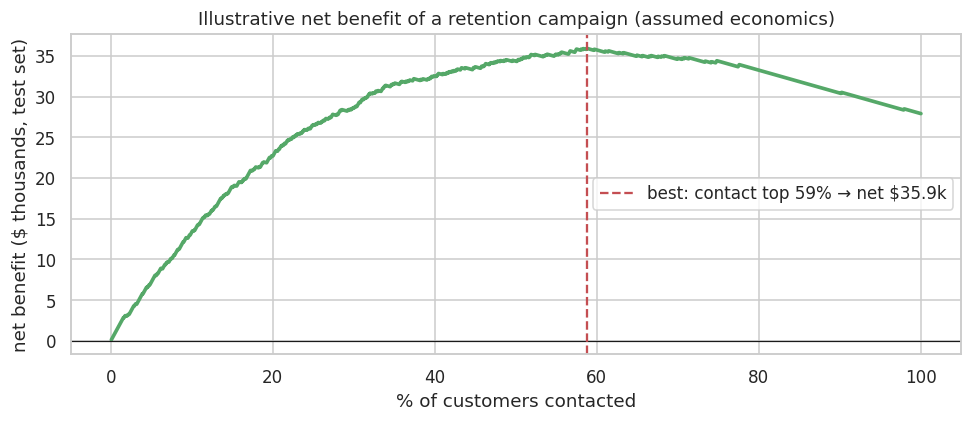

In [23]:
# ILLUSTRATIVE economics. These three numbers are ASSUMPTIONS, not facts about this dataset - replace them with your own.
COST_PER_CONTACT   = 20     # cost of one retention call/offer ($)
VALUE_PER_SAVED    = 500    # value of retaining one churner ($)
SUCCESS_RATE       = 0.30   # share of contacted true churners who are actually retained

contacted = np.arange(1, n + 1)
net = cum_tp * SUCCESS_RATE * VALUE_PER_SAVED - contacted * COST_PER_CONTACT
k_star = int(net.argmax()) + 1
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(frac * 100, net / 1000, color="C2", lw=2.4); ax.axhline(0, color="k", lw=.8)
ax.axvline(100 * k_star / n, color="r", ls="--", label=f"best: contact top {100*k_star/n:.0f}% → net ${net[k_star-1]/1000:,.1f}k")
ax.set_xlabel("% of customers contacted"); ax.set_ylabel("net benefit ($ thousands, test set)"); ax.set_title("Illustrative net benefit of a retention campaign (assumed economics)")
ax.legend(); plt.tight_layout(); plt.show()

**Choosing a cut-off**

- The F1-optimal threshold on out-of-fold training predictions is **0.58**. On the test set it gives precision 0.556, recall 0.741, F1 0.635 and flags 498 customers (35 % of the base), versus precision 0.509, recall 0.794, F1 0.620 and 584 flagged at 0.5. The test F1 (0.635) is close to the out-of-fold F1 (0.642) used to pick the threshold, so the choice generalises.
- F1 is only one definition of "best". The right threshold is a **business decision** about the relative cost of a wasted retention offer vs a lost customer, as the next two panels illustrate.

**Gains and lift**

- Ranking quality translates directly into targeting efficiency. Contacting the **top 10 %** of customers by predicted risk reaches **28.9 %** of all churners (lift 2.9×), the top 20 % reaches 50.5 %, the top 30 % reaches 66 % and the top 40 % reaches 78 %.
- The bottom two deciles contain only 2 churners among 281 customers (≈ 0.7 %), so these customers can be safely left alone.

**Illustrative economics (assumptions, not data).** With the placeholder numbers in the cell (\$20 per contact, \$500 value of a retained customer, 30 % success rate) a contact only pays for itself if the customer's churn probability exceeds \$20 / (0.30 × \$500) ≈ 13 %. The net-benefit curve therefore climbs steeply over the first 40 % of the ranking and is then **flat-topped** (peak at contacting ≈ 59 %, ≈ \$36k on the test set, with 40–80 % all within a few thousand dollars of that). The practical message: the exact cut-off matters much less than having a good ranking, and the right depth of campaign depends mainly on contact cost vs customer value. Replace the three assumed numbers with real ones before using this chart.

## 9. Calibration: can the scores be read as probabilities?

Class weighting deliberately inflates the minority class, so raw scores will over-state churn probabilities even though the *ranking* (and hence ROC-AUC) is unaffected. If the business wants "this customer has a 40 % chance of churning", the scores need calibrating.
We wrap the chosen model in `CalibratedClassifierCV` (Platt/sigmoid scaling, 5-fold, fitted on the training set only) and compare.

,ROC-AUC,Brier score (lower = better),Log-loss (lower = better),Mean predicted risk
XGBoost (as trained),0.8460,0.1643,0.4866,0.4100
XGBoost (calibrated),0.8475,0.1359,0.4187,0.2679
Actual churn rate (test),—,—,—,0.2654


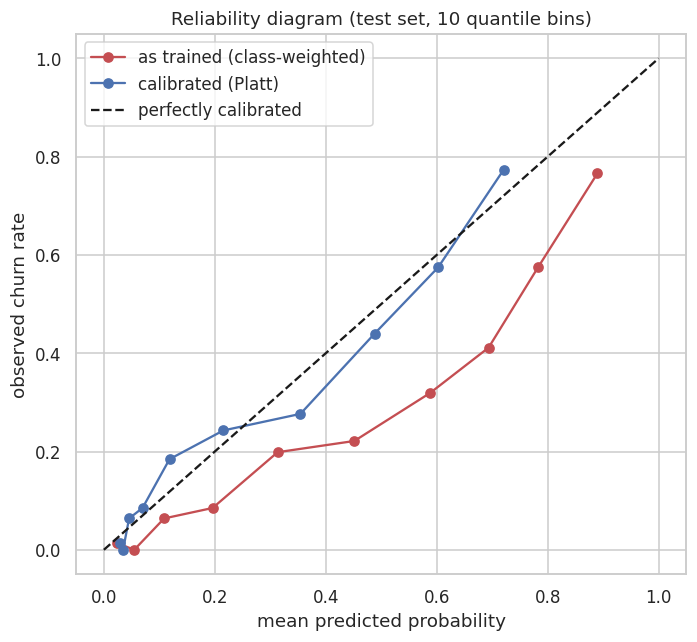

In [24]:
cal = CalibratedClassifierCV(clone(best_est), method="sigmoid", cv=5).fit(X_train, y_train)
p_cal = cal.predict_proba(X_test)[:, 1]

cmp = pd.DataFrame({
    "ROC-AUC": [roc_auc_score(y_t, p_best), roc_auc_score(y_t, p_cal)],
    "Brier score (lower = better)": [brier_score_loss(y_t, p_best), brier_score_loss(y_t, p_cal)],
    "Log-loss (lower = better)": [log_loss(y_t, p_best), log_loss(y_t, p_cal)],
    "Mean predicted risk": [p_best.mean(), p_cal.mean()],
}, index=[f"{best_name} (as trained)", f"{best_name} (calibrated)"])
cmp.loc["Actual churn rate (test)"] = [np.nan, np.nan, np.nan, y_t.mean()]
display(cmp.style.format("{:.4f}", na_rep="—"))

fig, ax = plt.subplots(figsize=(6.5, 6))
for p, lab, c in [(p_best, "as trained (class-weighted)", "C3"), (p_cal, "calibrated (Platt)", "C0")]:
    fp, mp = calibration_curve(y_t, p, n_bins=10, strategy="quantile")
    ax.plot(mp, fp, "o-", color=c, label=lab)
ax.plot([0, 1], [0, 1], "k--", label="perfectly calibrated"); ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed churn rate")
ax.set_title("Reliability diagram (test set, 10 quantile bins)"); ax.legend(); plt.tight_layout(); plt.show()

**Reading the calibration results**

- As trained, the class-weighted XGBoost **systematically over-states risk**: the mean predicted churn probability is **0.41** against an actual churn rate of **0.265**, and the red reliability curve sits below the diagonal across the whole range. This is expected, because `scale_pos_weight` deliberately inflates the minority class.
- Platt scaling fixes it: mean predicted risk becomes 0.268, Brier score falls from 0.164 to **0.136** and log-loss from 0.487 to **0.419**, and the blue curve hugs the diagonal (the remaining wiggles are within what ≈ 140 customers per bin would produce by chance).
- Ranking is essentially unchanged (ROC-AUC 0.846 → 0.848), so calibration costs nothing in discrimination.

**Practical rule:** use the raw model for *ranking* and thresholds tuned as in Section 8, but use the **calibrated** model whenever the score is quoted or used as a probability (e.g. expected-revenue-at-risk calculations). Note that the Random Forest, which re-weights the leaves rather than the loss, is closer to calibrated out of the box (test Brier 0.158 vs 0.164).

## 10. Feature importance: the top 10 drivers

No single importance measure is trustworthy on its own, so we use four and look for agreement:

1. **Random Forest impurity importance (MDI)**: built into the trees; fast but biased toward high-cardinality/continuous features.
2. **XGBoost gain**: average loss reduction when a feature is used for a split.
3. **Permutation importance** on the *test set*: how much does ROC-AUC fall when one *original* feature is shuffled? Model-agnostic, and because it shuffles the raw column (not individual dummies) it measures each feature as a whole.
4. **SHAP** values for XGBoost: unlike the others, they also show the **direction** of each effect.

Tree importances are first shown on the one-hot encoded columns (e.g. `Contract_Month-to-month`), then rolled up to the original features.

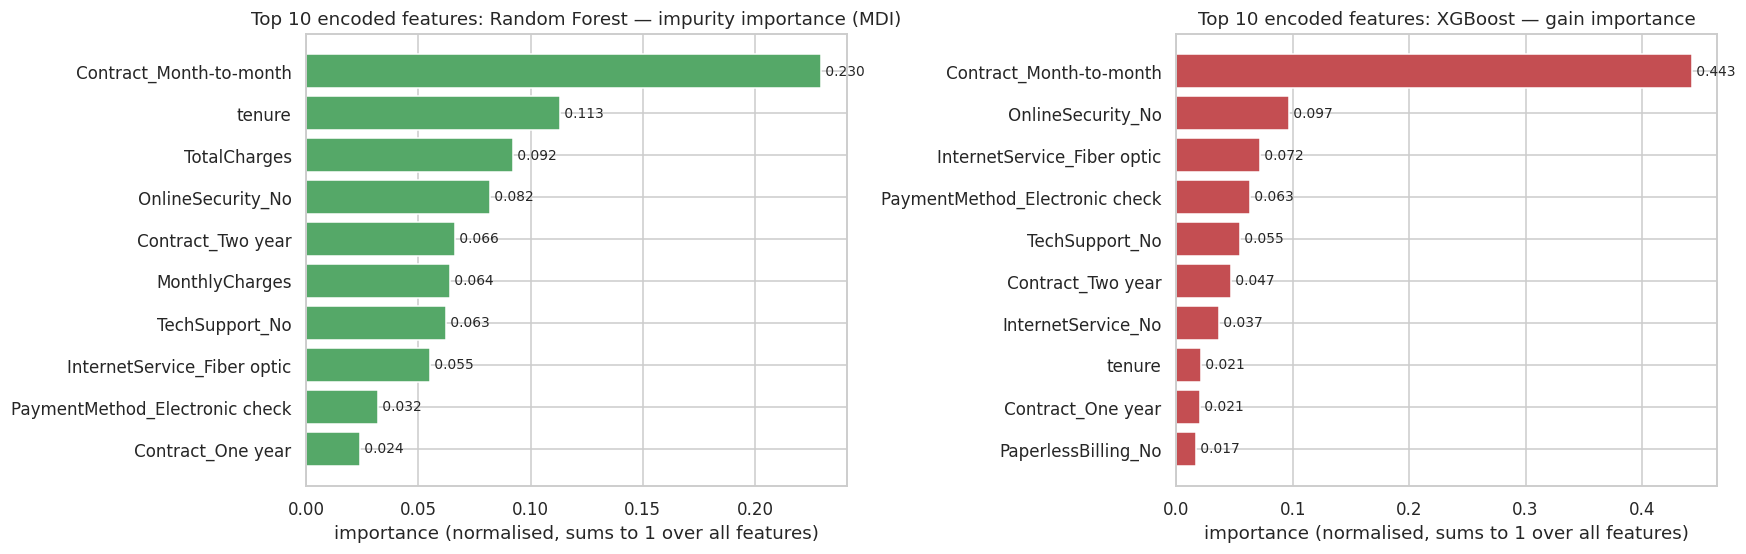

,RF MDI (feature level),XGB gain (feature level)
rank,,
1,Contract (0.320),Contract (0.511)
2,tenure (0.113),InternetService (0.113)
3,OnlineSecurity (0.092),OnlineSecurity (0.099)
4,TotalCharges (0.092),PaymentMethod (0.069)
5,InternetService (0.077),TechSupport (0.055)
6,TechSupport (0.071),PaperlessBilling (0.030)
7,MonthlyCharges (0.064),tenure (0.021)
8,PaymentMethod (0.044),StreamingMovies (0.018)
9,OnlineBackup (0.019),OnlineBackup (0.013)


In [25]:
rf_pipe  = final["Random Forest"];  xgb_pipe = final["XGBoost"]
rf_names, xgb_names = encoded_names(rf_pipe), encoded_names(xgb_pipe)

mdi  = pd.Series(rf_pipe.named_steps["m"].feature_importances_, index=rf_names).sort_values(ascending=False)
gain = pd.Series(xgb_pipe.named_steps["m"].feature_importances_, index=xgb_names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, s, ttl, c in [(axes[0], mdi, "Random Forest — impurity importance (MDI)", "C2"), (axes[1], gain, "XGBoost — gain importance", "C3")]:
    top = s.head(10)[::-1]
    ax.barh(top.index, top.values, color=c)
    for i, v in enumerate(top.values): ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)
    ax.set_title(f"Top 10 encoded features: {ttl}"); ax.set_xlabel("importance (normalised, sums to 1 over all features)")
plt.tight_layout(); plt.show()

# rolled up to original features
mdi_f  = mdi.groupby(to_feature).sum().sort_values(ascending=False)
gain_f = gain.groupby(to_feature).sum().sort_values(ascending=False)
display(pd.DataFrame({"RF MDI (feature level)": mdi_f.head(10).round(4).reset_index().apply(lambda r: f"{r.iloc[0]}  ({r.iloc[1]:.3f})", axis=1),
                      "XGB gain (feature level)": gain_f.head(10).round(4).reset_index().apply(lambda r: f"{r.iloc[0]}  ({r.iloc[1]:.3f})", axis=1)}).rename_axis("rank").set_index(pd.RangeIndex(1, 11, name="rank")))

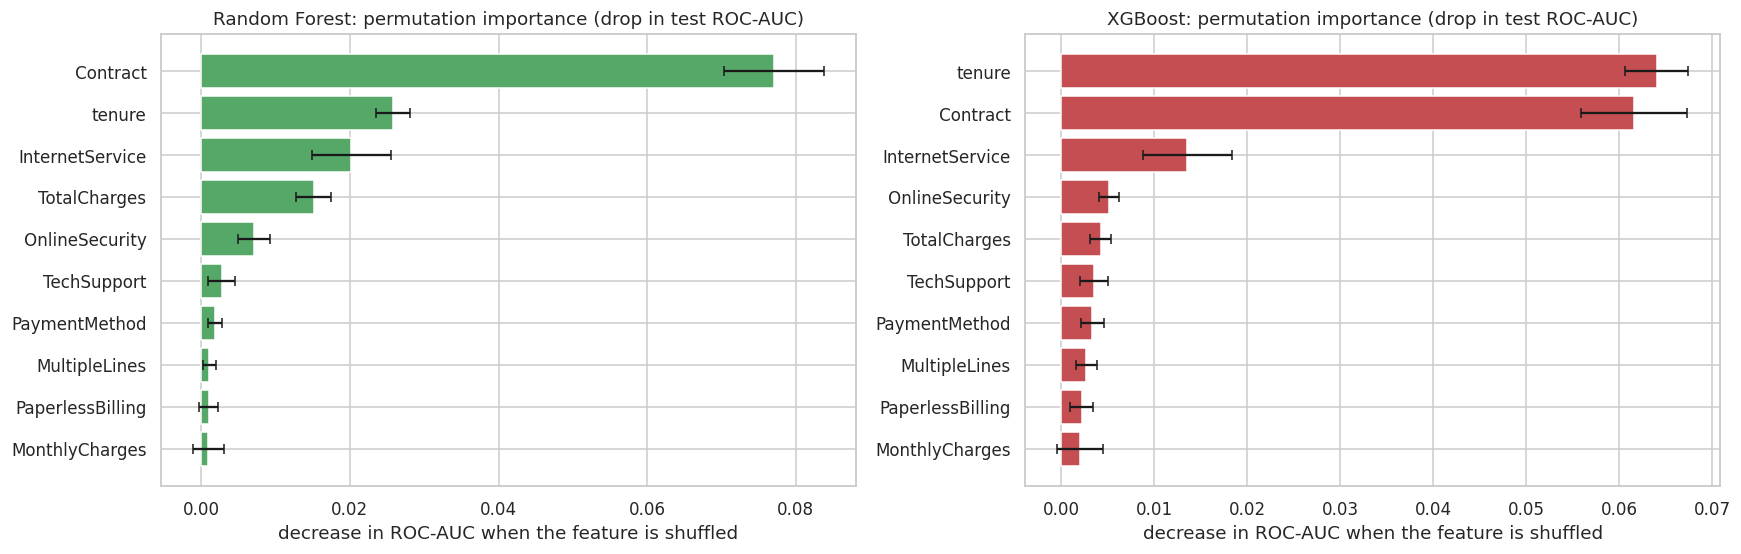

In [26]:
# permutation importance on the held-out test set (original features, scoring = ROC-AUC)
perm = {}
for nm, pipe in [("Random Forest", rf_pipe), ("XGBoost", xgb_pipe)]:
    r = permutation_importance(pipe, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=RS, n_jobs=1)
    perm[nm] = pd.DataFrame({"mean": r.importances_mean, "std": r.importances_std}, index=X_test.columns).sort_values("mean", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, (nm, d), c in zip(axes, perm.items(), ["C2", "C3"]):
    top = d.head(10)[::-1]
    ax.barh(top.index, top["mean"], xerr=top["std"], color=c, capsize=3)
    ax.set_title(f"{nm}: permutation importance (drop in test ROC-AUC)"); ax.set_xlabel("decrease in ROC-AUC when the feature is shuffled")
plt.tight_layout(); plt.show()

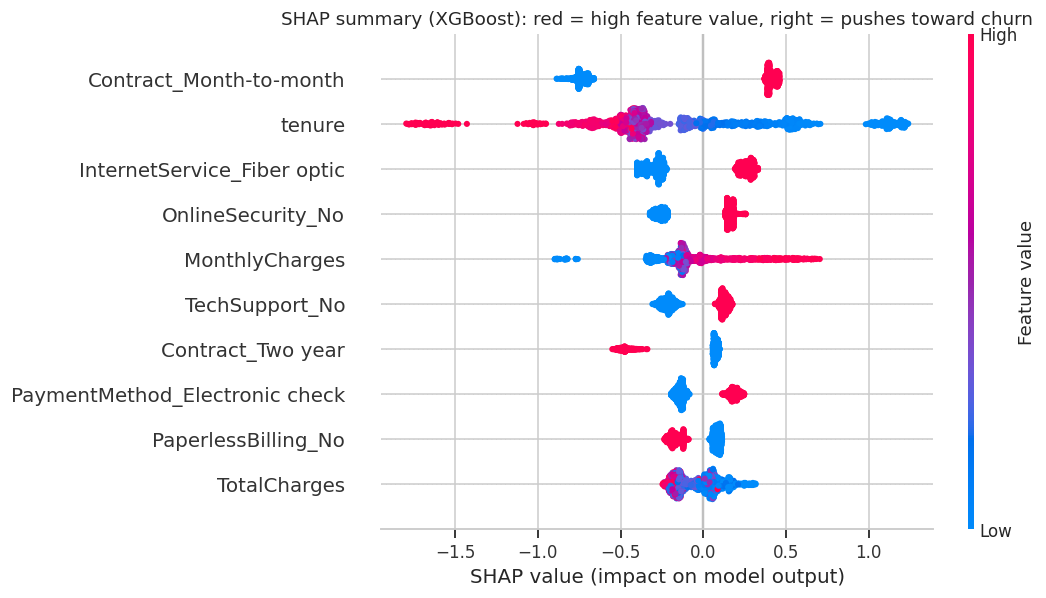

In [27]:
# SHAP for XGBoost: magnitude AND direction
Zte = encode(xgb_pipe, X_test)
explainer = shap.TreeExplainer(xgb_pipe.named_steps["m"])
sv = explainer.shap_values(Zte)

plt.figure(figsize=(10, 5.6))
shap.summary_plot(sv, Zte, max_display=10, show=False, plot_size=None)
plt.title("SHAP summary (XGBoost): red = high feature value, right = pushes toward churn"); plt.tight_layout(); plt.show()

shap_abs = pd.Series(np.abs(sv).mean(axis=0), index=Zte.columns)
shap_f = shap_abs.groupby(to_feature).sum().sort_values(ascending=False)

,RF MDI,XGB gain,RF permutation,XGB permutation,XGB SHAP,# methods in top 10,mean rank (where present)
Contract,1,1,1,2,1,5,1.2
tenure,2,7,2,1,2,5,2.8
InternetService,5,2,3,3,3,5,3.2
OnlineSecurity,3,3,5,4,4,5,3.8
TechSupport,6,5,6,6,6,5,5.8
PaymentMethod,8,4,7,7,7,5,6.6
TotalCharges,4,—,4,5,9,4,5.5
MonthlyCharges,7,—,10,10,5,4,8.0
PaperlessBilling,—,6,9,9,8,4,8.0
MultipleLines,—,—,8,8,10,3,8.7


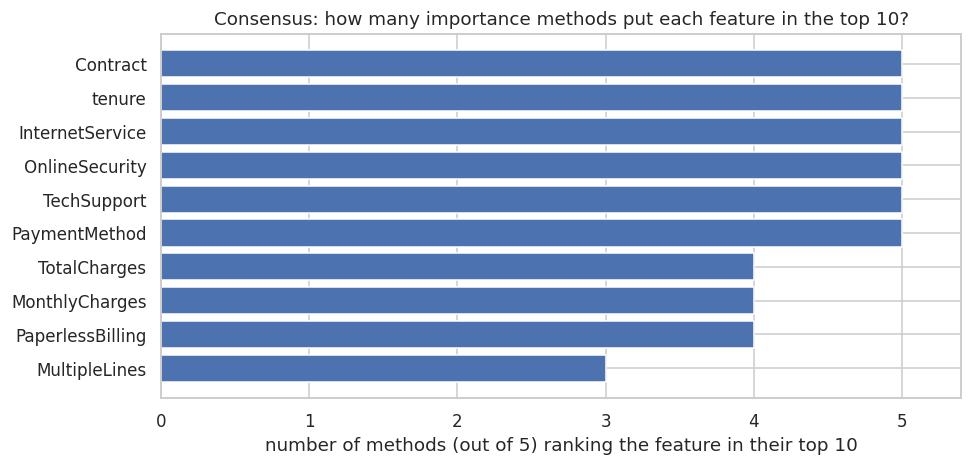

Features in the top 10 of at least 4 of 5 methods: ['Contract', 'tenure', 'InternetService', 'OnlineSecurity', 'TechSupport', 'PaymentMethod', 'TotalCharges', 'MonthlyCharges', 'PaperlessBilling']


In [28]:
# one consolidated view: top-10 features (original level) according to each method
methods = {"RF MDI": mdi_f, "XGB gain": gain_f, "RF permutation": perm["Random Forest"]["mean"].sort_values(ascending=False),
           "XGB permutation": perm["XGBoost"]["mean"].sort_values(ascending=False), "XGB SHAP": shap_f}
ranks = pd.DataFrame({m: pd.Series(np.arange(1, 11), index=s.head(10).index) for m, s in methods.items()})
ranks["# methods in top 10"] = ranks.notna().sum(axis=1)
ranks["mean rank (where present)"] = ranks.iloc[:, :5].mean(axis=1)
ranks = ranks.sort_values(["# methods in top 10", "mean rank (where present)"], ascending=[False, True])
display(ranks.style.format("{:.0f}", subset=list(methods) + ["# methods in top 10"], na_rep="—").format("{:.1f}", subset=["mean rank (where present)"]))

consensus = ranks[ranks["# methods in top 10"] >= 4].index.tolist()
fig, ax = plt.subplots(figsize=(9, 4.4))
top = ranks.head(10)[::-1]
ax.barh(top.index, top["# methods in top 10"], color="C0"); ax.set_xlim(0, 5.4); ax.set_xlabel("number of methods (out of 5) ranking the feature in their top 10")
ax.set_title("Consensus: how many importance methods put each feature in the top 10?"); plt.tight_layout(); plt.show()
print("Features in the top 10 of at least 4 of 5 methods:", consensus)

**What drives churn?**

Five independent views agree strongly. Six features appear in the top 10 of **all five** methods, and three more in four of five:

| Consensus drivers | Direction (from SHAP) | Evidence |
|---|---|---|
| **Contract** | Month-to-month → much higher churn; two-year → much lower | #1 in RF MDI, XGB gain, RF permutation and SHAP; #2 in XGB permutation. Shuffling it costs the RF ≈ 0.077 AUC, the largest single drop. |
| **tenure** | Short tenure → higher churn; long tenure → lower | #1 in XGB permutation (−0.064 AUC), #2 in RF permutation and SHAP |
| **InternetService** | Fibre optic → higher churn | rank 2–3 in four methods (5th in RF impurity importance) |
| **OnlineSecurity** | No online security → higher churn | top 5 in all methods |
| **TechSupport** | No tech support → higher churn | rank 5–6 in all methods |
| **PaymentMethod** | Electronic check → higher churn | rank 4–8 |
| TotalCharges, MonthlyCharges, PaperlessBilling | Higher monthly charges and paperless billing → higher churn; TotalCharges is mixed | in the top 10 of four methods |

**Interpretation and caveats**

- **The story is consistent with the EDA:** customers on flexible month-to-month plans, early in their lifetime, on fibre internet without security/support add-ons, and paying by electronic check are the churn-prone segment. Actionable levers include moving month-to-month customers to longer contracts, bundling security/support for fibre customers, and looking at why fibre customers leave.
- **Importance is not causation.** These are predictive associations from observational data; for example, "no tech support" may be a marker of price-sensitive customers rather than a cause of leaving. Any intervention should be tested (A/B test) rather than assumed.
- **Correlated features share credit.** `TotalCharges` ≈ tenure × `MonthlyCharges` (r ≈ 0.9996), so their importances are split between them and differ by method (e.g. `MonthlyCharges` is #5 for SHAP but has a permutation importance indistinguishable from zero, because when it is shuffled the model can recover most of the information from `tenure` and `TotalCharges`). Read these three as a group.
- **Impurity importance (MDI) is biased** toward continuous and multi-level features, which is why the permutation and SHAP views are included and why we trust the consensus rather than any one ranking.
- **Absent from every top 10:** gender, partner, dependents, senior citizen, phone service and device protection. Senior citizens showed a high raw churn rate in the EDA (42 %), but the models do not need the flag once contract, services and payment method are known, a reminder that a raw association is not the same as unique predictive value.

## 11. Conclusions

1. **Target achieved.** The best model, a **class-weighted, tuned XGBoost**, reaches **test ROC-AUC 0.846 (95 % CI 0.823–0.867)**. Random Forest reaches 0.844 and the logistic-regression yardstick 0.841. Every confidence interval and every cross-validation fold is above the required 0.80.
2. **Cleaning mattered in a small but principled way.** The 11 blank `TotalCharges` values all belong to brand-new customers (`tenure = 0`), so they were set to \$0, not imputed with a median, and the rule was asserted in code.
3. **Class weighting beat SMOTE.** Weighting left ROC-AUC unchanged and turned a recall of ≈ 0.5 into ≈ 0.8 at the default cut-off; `SMOTENC` (done correctly, before one-hot encoding, inside the pipeline) lowered AUC by ≈ 0.006 in 9 of 10 fold comparisons.
4. **Do not oversell the ensembles.** The paired bootstrap shows XGBoost, Random Forest and a tuned logistic regression are statistically indistinguishable on this data. The ensembles' value here is a slightly better ranking at low false-alarm rates and PR-AUC, not a step change. If interpretability or simplicity matter, the linear model is a legitimate choice.
5. **Operationally:** at a tuned threshold of 0.58 the model finds ≈ 74 % of churners with ≈ 56 % precision; contacting the top 20 % of customers by risk reaches half of all churners, and the bottom 20 % can be ignored. The threshold and campaign depth should be set from real contact costs and customer value (Section 8's numbers are placeholders).
6. **Scores are not probabilities until calibrated.** Class weighting inflates them (mean 0.41 vs actual 0.265); Platt scaling fixes this at no cost in AUC and should be used if probabilities are quoted.
7. **Drivers:** contract type, tenure, fibre internet, missing security/support add-ons and electronic-check payment dominate, consistently across five importance methods. These are predictive, not causal, associations.

**Limitations and next steps.** This is a single cross-sectional snapshot with no time dimension, so we cannot test how the model degrades as customers or pricing change, and a time-based split would be a stricter evaluation. Natural extensions: engineered features (number of add-on services, charge per month of tenure vs current charge), gradient-boosting with monotonic constraints, cost-sensitive threshold optimisation using real economics, and an uplift model (who is *persuadable*, not just who is likely to leave).